# Kesit İstatistik — Tahmin teorisi

Kurulum: `python -m pip install -r requirements.txt`

Python 3.11+ ve Jupyter/VS Code ile aç. Önce kurulum hücresini, sonra ders hücrelerini çalıştır. Hazır çıktılar doğrulanan çalıştırmadan alınmıştır; kodu değiştirdiğinde hücreyi yeniden çalıştır. Her ders kendi sentetik verisini üretir. İnternet/API/şirket verisi gerektirmez.


## Yanlılık, tutarlılık ve ortalama kare hata

Yanlı ama daha kararlı tahmin bazen daha iyi olabilir mi?

**Veri:** Kod içindeki sabit tohumlu sentetik veri. Gerçek şirket verisi içermez.

**Grafiği oku:** Sapma ve varyansın toplamının MSE’ye katkısını oku.

**Yorum sınırı:** Sonuç seçilmiş simülasyon evrenine aittir; tek kazanan evrensel değildir.

**Alıştırma:** Gerçek ortalamayı 1’den 0’a değiştir; küçültmenin zararını/kazancını yeniden değerlendir.

**Kabul ölçütü:** İlk çıktıyı, tek değişiklikten sonraki çıktıyı, grafikteki farkı ve yorum sınırını dört cümlede kaydet.


              tahmin  yanlilik   varyans       MSE
0           Ortalama  0.007149  0.495353  0.495404
1  0 yönüne küçültme -0.345353  0.209287  0.328556


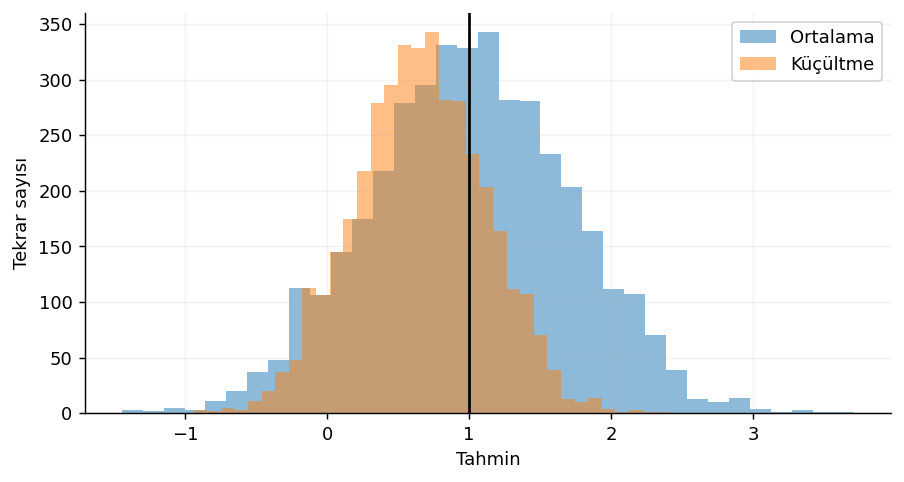

In [61]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold, KFold
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression, BayesianRidge
from sklearn.metrics import mean_squared_error, log_loss, brier_score_loss, roc_auc_score, average_precision_score
from sklearn.datasets import make_classification, make_moons
import statsmodels.api as sm
import statsmodels.formula.api as smf
rng=np.random.default_rng(20261108)
np.set_printoptions(precision=4, suppress=True)
pd.set_option('display.max_columns',8)
plt.rcParams.update({'figure.figsize':(8,4),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})

truth=1.;samples=rng.normal(truth,2,(4000,8));raw=samples.mean(axis=1);shrink=.65*raw
rows=[]
for name,v in [('Ortalama',raw),('0 yönüne küçültme',shrink)]:
 bias=v.mean()-truth;var=v.var();mse=np.mean((v-truth)**2);rows.append([name,bias,var,mse]);assert abs(mse-bias**2-var)<1e-10
print(pd.DataFrame(rows,columns=['tahmin','yanlilik','varyans','MSE']));plt.hist(raw,bins=35,alpha=.5,label='Ortalama');plt.hist(shrink,bins=35,alpha=.5,label='Küçültme');plt.axvline(truth,c='black');plt.legend();plt.xlabel('Tahmin');plt.ylabel('Tekrar sayısı')

## En çok olabilirlik ve momentler yöntemi

Sayım verisinde MLE ve momentler nerede buluşur?

**Veri:** Kod içindeki sabit tohumlu sentetik veri. Gerçek şirket verisi içermez.

**Grafiği oku:** Olabilirlik tepesinin örneklem ortalamasıyla çakışmasını izle.

**Yorum sınırı:** Poisson modeli ortak hız ve uygun maruziyet varsayar; aşırı saçılmayı çözmez.

**Alıştırma:** Üretim hızını 4’ten 9’a değiştir; hız tahminini ve eğriyi yeniden hesapla.

**Kabul ölçütü:** İlk çıktıyı, tek değişiklikten sonraki çıktıyı, grafikteki farkı ve yorum sınırını dört cümlede kaydet.


{'MLE': np.float64(3.9125), 'momentler': np.float64(3.9125), 'n': 80}


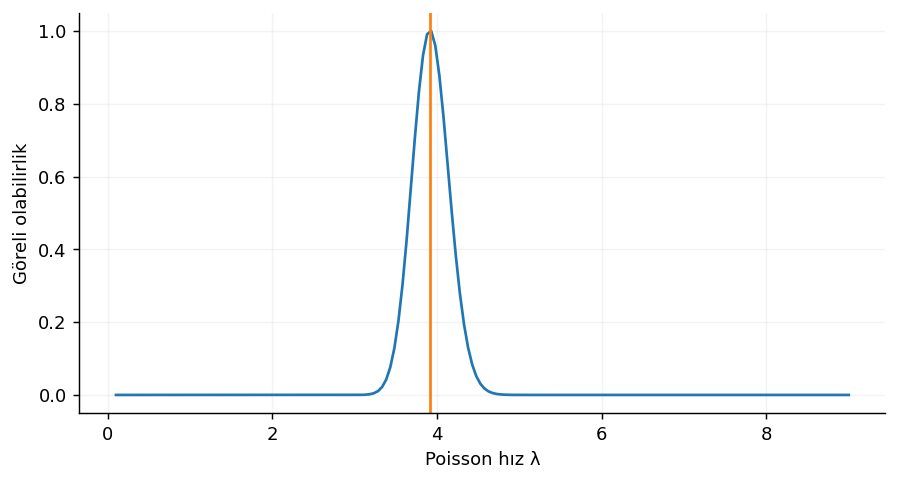

In [62]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold, KFold
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression, BayesianRidge
from sklearn.metrics import mean_squared_error, log_loss, brier_score_loss, roc_auc_score, average_precision_score
from sklearn.datasets import make_classification, make_moons
import statsmodels.api as sm
import statsmodels.formula.api as smf
rng=np.random.default_rng(20261108)
np.set_printoptions(precision=4, suppress=True)
pd.set_option('display.max_columns',8)
plt.rcParams.update({'figure.figsize':(8,4),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})

x=rng.poisson(4,80);mle=x.mean();grid=np.linspace(.1,9,180);ll=np.array([stats.poisson.logpmf(x,v).sum() for v in grid])
print({'MLE':mle,'momentler':x.mean(),'n':len(x)})
plt.plot(grid,np.exp(ll-ll.max()));plt.axvline(mle,c='tab:orange');plt.xlabel('Poisson hız λ');plt.ylabel('Göreli olabilirlik')

## Fisher bilgisi ve olabilirlik oranı

Olabilirlik oranı ile Wald yaklaşımı aynı sonucu verir mi?

**Veri:** Kod içindeki sabit tohumlu sentetik veri. Gerçek şirket verisi içermez.

**Grafiği oku:** İki aralığın özellikle küçük sayımlarda ayrılabildiğini gör.

**Yorum sınırı:** Wilks χ² ve Wald yaklaşımları sınırda/küçük örneklemde zayıflayabilir.

**Alıştırma:** k=7,n=40 yerine k=1,n=10 kullan; simetrik aralığın sınır sorununu incele.

**Kabul ölçütü:** İlk çıktıyı, tek değişiklikten sonraki çıktıyı, grafikteki farkı ve yorum sınırını dört cümlede kaydet.


{'MLE': 0.175, 'Fisher_bilgi': 277.0562770562771, 'Wald': (np.float64(0.05724697456116043), np.float64(0.2927530254388395)), 'LR_profil': (np.float64(0.08016406406406408), np.float64(0.3103482482482483))}


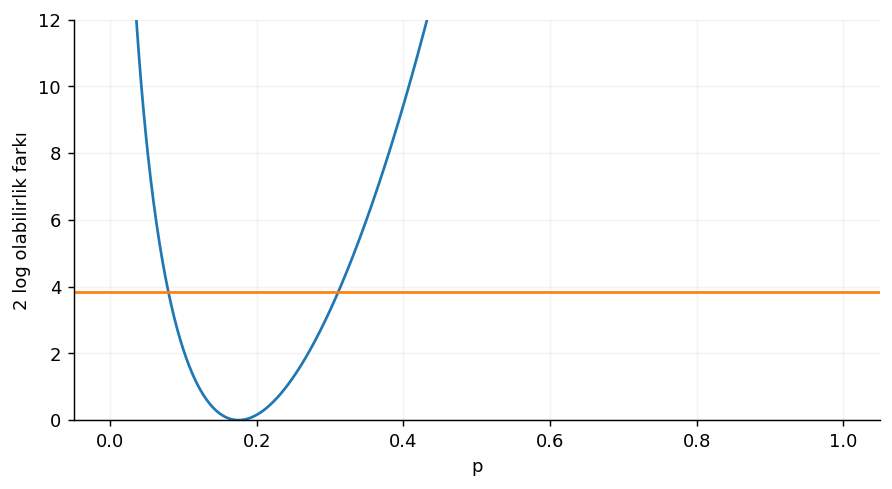

In [63]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold, KFold
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression, BayesianRidge
from sklearn.metrics import mean_squared_error, log_loss, brier_score_loss, roc_auc_score, average_precision_score
from sklearn.datasets import make_classification, make_moons
import statsmodels.api as sm
import statsmodels.formula.api as smf
rng=np.random.default_rng(20261108)
np.set_printoptions(precision=4, suppress=True)
pd.set_option('display.max_columns',8)
plt.rcParams.update({'figure.figsize':(8,4),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})

k,n=7,40;p=k/n;grid=np.linspace(.0001,.9999,1000);ll=stats.binom.logpmf(k,n,grid);best=stats.binom.logpmf(k,n,p);lr=2*(best-ll);ok=grid[lr<=stats.chi2.ppf(.95,1)]
info=n/(p*(1-p));print({'MLE':p,'Fisher_bilgi':info,'Wald':(p-1.96/np.sqrt(info),p+1.96/np.sqrt(info)),'LR_profil':(ok.min(),ok.max())})
plt.plot(grid,lr);plt.axhline(stats.chi2.ppf(.95,1),c='tab:orange');plt.ylim(0,12);plt.xlabel('p');plt.ylabel('2 log olabilirlik farkı')

## AIC, BIC ve model seçimi

Daha esnek modelin daha iyi uyumu neye mal olur?

**Veri:** Kod içindeki sabit tohumlu sentetik veri. Gerçek şirket verisi içermez.

**Grafiği oku:** AIC/BIC ile ayrı test hatasını aynı dereceler için karşılaştır.

**Yorum sınırı:** Bilgi kriterleri aynı yanıt/olabilirlik ve uygun parametre sayısıyla karşılaştırılır; test seti model seçmek için tüketilmez.

**Alıştırma:** n=100 yerine n=30 kullan; yüksek derecenin cezasını ve test hatasını karşılaştır.

**Kabul ölçütü:** İlk çıktıyı, tek değişiklikten sonraki çıktıyı, grafikteki farkı ve yorum sınırını dört cümlede kaydet.


   derece         AIC         BIC  test_MSE
0       1  312.586065  317.796405  1.726379
1       2  263.138778  270.954289  1.028556
2       3  260.656314  271.076995  1.055818
3       4  262.028073  275.053924  1.060199
4       5  262.396361  278.027382  1.065489
5       6  264.395994  282.632185  1.065357


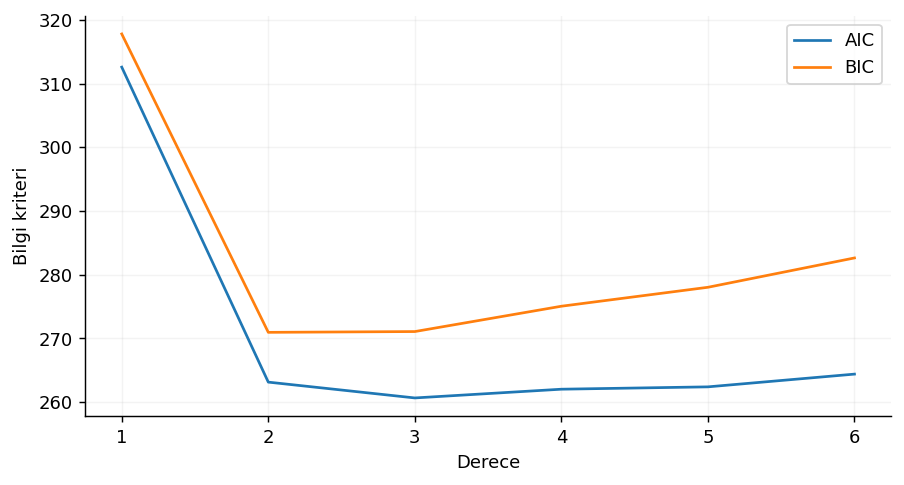

In [64]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold, KFold
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression, BayesianRidge
from sklearn.metrics import mean_squared_error, log_loss, brier_score_loss, roc_auc_score, average_precision_score
from sklearn.datasets import make_classification, make_moons
import statsmodels.api as sm
import statsmodels.formula.api as smf
rng=np.random.default_rng(20261108)
np.set_printoptions(precision=4, suppress=True)
pd.set_option('display.max_columns',8)
plt.rcParams.update({'figure.figsize':(8,4),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})

x=np.linspace(-2,2,100);y=2+x+.7*x*x+rng.normal(0,1,len(x));xt=rng.uniform(-2,2,500);yt=2+xt+.7*xt*xt+rng.normal(0,1,500);rows=[]
for degree in range(1,7):
 model=sm.OLS(y,np.vander(x,degree+1,increasing=True)).fit();pred=model.predict(np.vander(xt,degree+1,increasing=True));rows.append([degree,model.aic,model.bic,mean_squared_error(yt,pred)])
tab=pd.DataFrame(rows,columns=['derece','AIC','BIC','test_MSE']);print(tab);plt.plot(tab.derece,tab.AIC,label='AIC');plt.plot(tab.derece,tab.BIC,label='BIC');plt.xlabel('Derece');plt.ylabel('Bilgi kriteri');plt.legend()